# D03 — Économétrie de la moyenne : ARIMA · SARIMA · SARIMAX

> Toutes les estimations sont réalisées sur la **fenêtre d'apprentissage uniquement**.
> Les paramètres sont ensuite gelés et appliqués à la série complète via `res.apply()`.
> Aucune information hors-apprentissage ne contamine les estimations.


In [1]:
import os
import sys
import warnings
from pathlib import Path

# --- Trouver la racine du projet (contient configs/frozen.yaml) ---
_candidate = Path.cwd()
for _ in range(6):
    if (_candidate / "configs" / "frozen.yaml").exists():
        break
    _candidate = _candidate.parent
else:
    raise RuntimeError("Racine du projet introuvable depuis " + str(Path.cwd()))
root = _candidate
os.chdir(str(root))
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
# -----------------------------------------------------------------

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from src.data import load_closes
from src.features import build_frame, split
from src.models.econometrics import (
    FitResult,
    fit_state_space,
    naive_zero,
    naive_last,
    historical_mean,
    select_arima_order,
    grille_arima,
    adf_test,
    residual_diagnostics,
    metrics,
    diebold_mariano,
)

REP_D03 = root / "reports" / "d03"
REP_FIG = REP_D03 / "figures"
REP_FIG.mkdir(parents=True, exist_ok=True)

print("Imports OK")
print("  Rapports :", REP_D03)
print("  Figures  :", REP_FIG)


Imports OK
  Rapports : C:\Users\elbid\Documents\TREDING INTELEGENT\dia-quant-lab\reports\d03
  Figures  : C:\Users\elbid\Documents\TREDING INTELEGENT\dia-quant-lab\reports\d03\figures


In [2]:
closes = load_closes()
frame  = build_frame(closes)
dec    = split(frame)

train_mask = pd.Series(False, index=frame.index)
train_mask.loc[dec["train"].index] = True

print("Données chargées")
print("  Total séances   :", len(frame))
print("  Apprentissage   :", int(train_mask.sum()))
print("  Validation      :", len(dec["validation"]))
print("  Test            :", len(dec["test"]))
print("  Période totale  :", str(frame.index[0].date()), "->", str(frame.index[-1].date()))


Données chargées
  Total séances   : 2218
  Apprentissage   : 1258
  Validation      : 502
  Test            : 458
  Période totale  : 2018-01-03 -> 2026-10-29


## 1. Test de stationnarité — ADF

**H0** : présence d'une racine unitaire (série non stationnaire).
Rejet de H0 à 5 % -> rendements log stationnaires, **d = 0 justifié**.
Test effectué sur la fenêtre d'apprentissage uniquement.


In [3]:
adf_dia = adf_test(dec["train"]["dia_ret"])
adf_spy = adf_test(dec["train"]["spy_ret"])

df_adf = pd.DataFrame([
    {
        "Série": "DIA (apprentissage)",
        "Stat ADF": adf_dia["stat"],
        "p-value": adf_dia["pval"],
        "Critique 1%": adf_dia["critique_1pct"],
        "Critique 5%": adf_dia["critique_5pct"],
        "Stationnaire (p<0.05)": adf_dia["stationnaire"],
    },
    {
        "Série": "SPY (apprentissage)",
        "Stat ADF": adf_spy["stat"],
        "p-value": adf_spy["pval"],
        "Critique 1%": adf_spy["critique_1pct"],
        "Critique 5%": adf_spy["critique_5pct"],
        "Stationnaire (p<0.05)": adf_spy["stationnaire"],
    },
])
display(df_adf)


,Série,Stat ADF,p-value,Critique 1%,Critique 5%,Stationnaire (p<0.05)
0,DIA (apprentissage),-10.9022,0.0,-3.4356,-2.8639,True
1,SPY (apprentissage),-10.8555,0.0,-3.4356,-2.8639,True


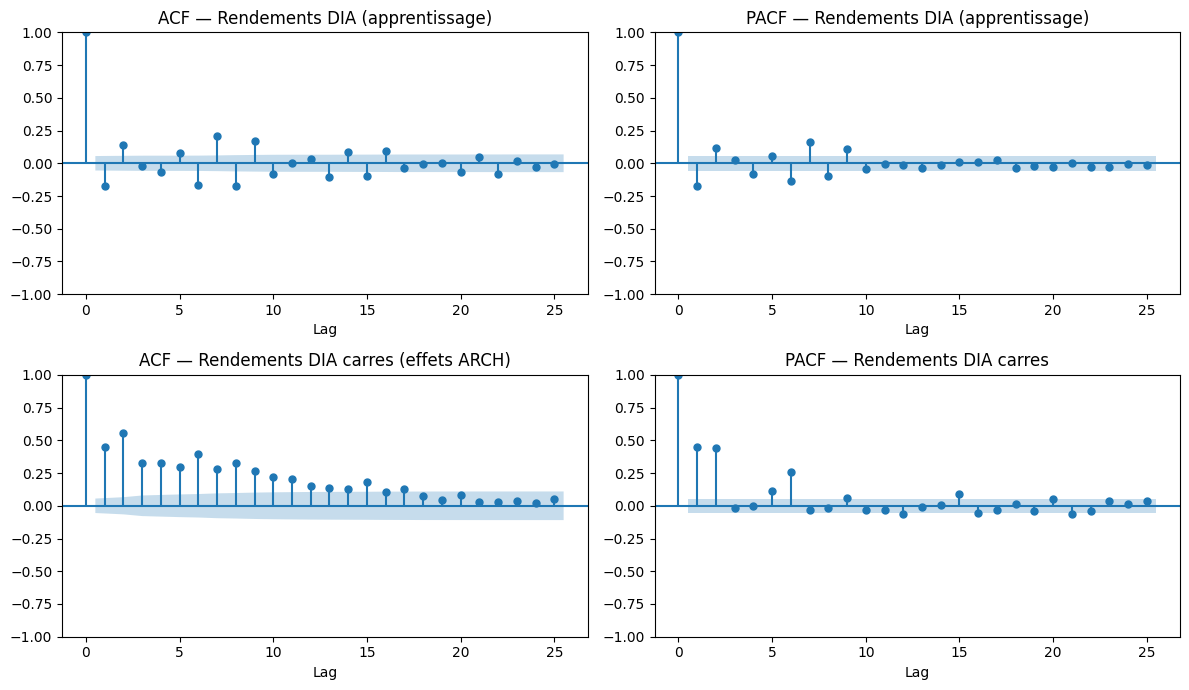

Figure sauvegardée : C:\Users\elbid\Documents\TREDING INTELEGENT\dia-quant-lab\reports\d03\figures\acf_pacf_dia.png


In [4]:
r_train = dec["train"]["dia_ret"].dropna()

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
plot_acf(r_train,     lags=25, ax=axes[0, 0],
         title="ACF — Rendements DIA (apprentissage)")
plot_pacf(r_train,    lags=25, ax=axes[0, 1],
          title="PACF — Rendements DIA (apprentissage)")
plot_acf(r_train**2,  lags=25, ax=axes[1, 0],
         title="ACF — Rendements DIA carres (effets ARCH)")
plot_pacf(r_train**2, lags=25, ax=axes[1, 1],
          title="PACF — Rendements DIA carres")

for ax in axes.flat:
    ax.set_xlabel("Lag")
plt.tight_layout()
fig.savefig(REP_FIG / "acf_pacf_dia.png", dpi=120, bbox_inches="tight")
plt.show()
print("Figure sauvegardée :", str(REP_FIG / "acf_pacf_dia.png"))


## 2. Grille ARIMA(p, 0, q) — sélection par AIC

d = 0 : les rendements log sont stationnaires (voir ADF).
Grille : p in [0, 3], q in [0, 3] selon `configs/frozen.yaml`.
Estimation sur l'apprentissage uniquement — l'AIC sert de critère de sélection.


In [5]:
print("Calcul de la grille ARIMA — peut prendre ~1 min...")
df_grille = grille_arima(frame, train_mask)

p_best = int(df_grille.iloc[0]["p"])
q_best = int(df_grille.iloc[0]["q"])
meilleur_ordre = (p_best, 0, q_best)

print("Meilleur ordre AIC :", meilleur_ordre)
print()
print("Top 8 par AIC :")
display(df_grille.head(8))


Calcul de la grille ARIMA — peut prendre ~1 min...


Meilleur ordre AIC : (0, 0, 3)

Top 8 par AIC :


,ordre,p,q,AIC,BIC
0,"ARIMA(0,0,3)",0,3,-7267.17,-7241.48
1,"ARIMA(0,0,2)",0,2,-7267.14,-7246.59
2,"ARIMA(1,0,2)",1,2,-7266.58,-7240.89
3,"ARIMA(2,0,0)",2,0,-7265.81,-7245.26
4,"ARIMA(2,0,2)",2,2,-7265.79,-7234.96
5,"ARIMA(1,0,3)",1,3,-7264.99,-7234.16
6,"ARIMA(3,0,0)",3,0,-7264.56,-7238.87
7,"ARIMA(2,0,1)",2,1,-7263.53,-7237.85


In [6]:
print("Estimation ARIMA" + str(meilleur_ordre) + " sur l'apprentissage...")
res_arima = fit_state_space(
    frame, train_mask,
    order=meilleur_ordre,
    seasonal_order=(0, 0, 0, 0),
    with_exog=False,
)
print("AIC = " + str(round(res_arima.aic, 2)) + "  |  BIC = " + str(round(res_arima.bic, 2)))
print("Temps estimation : " + str(round(res_arima.fit_seconds, 2)) + " s")
print()
df_params = pd.DataFrame({
    "Parametre": res_arima.params.index,
    "Valeur": res_arima.params.values.round(6),
    "p-value": res_arima.pvalues.values.round(4),
    "Significatif (5%)": (res_arima.pvalues.values < 0.05),
})
display(df_params)


Estimation ARIMA(0, 0, 3) sur l'apprentissage...


AIC = -7267.17  |  BIC = -7241.48
Temps estimation : 1.42 s



,Parametre,Valeur,p-value,Significatif (5%)
0,intercept,0.000307,0.4478,False
1,ma.L1,-0.157549,0.0000,True
2,ma.L2,0.152762,0.0000,True
3,ma.L3,-0.041316,0.0025,True
4,sigma2,0.000180,0.0000,True


## 3. Extensions saisonnières — SARIMA(p,0,q)(P,0,Q)[5]

Période saisonnière : **s = 5** (cycle hebdomadaire, 5 séances de bourse).
Ordre non-saisonnier fixé au meilleur ordre ARIMA trouvé par la grille.
Trois variantes testées : (P, D, Q) = (1,0,0), (0,0,1), (1,0,1).
Les p-values des termes saisonniers indiquent si la composante est justifiée.


In [ ]:
sarima_configs = [(1, 0, 0, 5), (0, 0, 1, 5), (1, 0, 1, 5)]
resultats_sarima = {}

for P, D, Q, s in sarima_configs:
    nom = (
        "SARIMA("
        + str(p_best) + ",0," + str(q_best)
        + ")(" + str(P) + "," + str(D) + "," + str(Q)
        + ")[" + str(s) + "]"
    )
    print("Estimation", nom, "...")
    try:
        res = fit_state_space(
            frame, train_mask,
            order=meilleur_ordre,
            seasonal_order=(P, D, Q, s),
            with_exog=False,
            nom=nom,
        )
        resultats_sarima[nom] = res
        print(
            "  AIC = " + str(round(res.aic, 2))
            + "  |  BIC = " + str(round(res.bic, 2))
            + "  |  t_fit = " + str(round(res.fit_seconds, 2)) + " s"
        )
        df_p = pd.DataFrame({
            "Parametre": res.params.index,
            "Valeur": res.params.values.round(6),
            "p-value": res.pvalues.values.round(4),
            "Significatif (5%)": (res.pvalues.values < 0.05),
        })
        display(df_p)
    except Exception as exc:
        print("  ECHEC :", exc)
        resultats_sarima[nom] = None


Estimation SARIMA(0,0,3)(1,0,0)[5] ...


  AIC = -7266.09  |  BIC = -7235.27  |  t_fit = 0.86 s


,Parametre,Valeur,p-value,Significatif (5%)
0,intercept,0.000298,0.4630,False
1,ma.L1,-0.154772,0.0000,True
2,ma.L2,0.150312,0.0000,True
3,ma.L3,-0.027891,0.0411,True
4,ar.S.L5,0.029769,0.0521,False
5,sigma2,0.000180,0.0000,True


Estimation SARIMA(0,0,3)(0,0,1)[5] ...


  AIC = -7266.25  |  BIC = -7235.42  |  t_fit = 2.52 s


,Parametre,Valeur,p-value,Significatif (5%)
0,intercept,0.000310,0.4598,False
1,ma.L1,-0.151792,0.0000,True
2,ma.L2,0.148528,0.0000,True
3,ma.L3,-0.032772,0.0165,True
4,ma.S.L5,0.032664,0.0324,True
5,sigma2,0.000180,0.0000,True


Estimation SARIMA(0,0,3)(1,0,1)[5] ...


  AIC = -7263.21  |  BIC = -7227.25  |  t_fit = 2.78 s


,Parametre,Valeur,p-value,Significatif (5%)
0,intercept,0.000210,0.7834,False
1,ma.L1,-0.156971,0.0000,True
2,ma.L2,0.151701,0.0000,True
3,ma.L3,-0.039613,0.0077,True
4,ar.S.L5,0.316871,0.9001,False
5,ma.S.L5,-0.311410,0.9019,False
6,sigma2,0.000180,0.0000,True


## 4. SARIMAX — variable exogène SPY retard 1

**Exogène** : spy_ret_{t-1} (rendement SPY de la veille, connu à la clôture t-1).
La décision en t utilise SPY(t-1) — aucune information future n'est utilisée.
Ordre non-saisonnier : meilleur ordre ARIMA. Pas de composante saisonnière.


In [8]:
nom_sarimax = (
    "SARIMAX(" + str(p_best) + ",0," + str(q_best) + ")+SPY(t-1)"
)
print("Estimation", nom_sarimax, "...")
res_sarimax = fit_state_space(
    frame, train_mask,
    order=meilleur_ordre,
    seasonal_order=(0, 0, 0, 0),
    with_exog=True,
    nom=nom_sarimax,
)
print("AIC = " + str(round(res_sarimax.aic, 2)) + "  |  BIC = " + str(round(res_sarimax.bic, 2)))
print("Temps estimation : " + str(round(res_sarimax.fit_seconds, 2)) + " s")
print()
df_sarimax_params = pd.DataFrame({
    "Parametre": res_sarimax.params.index,
    "Valeur": res_sarimax.params.values.round(6),
    "p-value": res_sarimax.pvalues.values.round(4),
    "Significatif (5%)": (res_sarimax.pvalues.values < 0.05),
})
display(df_sarimax_params)


Estimation SARIMAX(0,0,3)+SPY(t-1) ...


AIC = -7259.08  |  BIC = -7228.26
Temps estimation : 2.27 s



,Parametre,Valeur,p-value,Significatif (5%)
0,intercept,0.000281,0.4573,False
1,spy_ret,0.066614,0.4210,False
2,ma.L1,-0.220878,0.0028,True
3,ma.L2,0.162163,0.0000,True
4,ma.L3,-0.050778,0.0016,True
5,sigma2,0.000180,0.0000,True


## 5. Diagnostics des résidus

Modèle de référence : meilleur ARIMA.
Tests appliqués aux résidus d'apprentissage (premiers 10 écartés — initialisation du filtre Kalman) :
- **Ljung-Box** (H0 : pas d'autocorrélation)
- **Ljung-Box sur r²** (H0 : pas d'effet ARCH)
- **Jarque-Bera** (H0 : normalité)


,Lag,LB stat (residus),p-value (residus),Rejette H0 (5%),LB stat (residus2),p-value (residus2),ARCH detecte (5%)
0,5,3.0291,0.695493,False,634.5522,0.0,True
1,10,77.6441,0.000000,True,1191.0545,0.0,True
2,20,104.1700,0.000000,True,1390.0792,0.0,True



Jarque-Bera : stat = 10970.6001  |  p-value = 0.0
Normalite (p>=0.05) : False
Asymetrie : -0.8707
Exces de kurtosis : 17.4791
Nombre de residus utilises : 1238


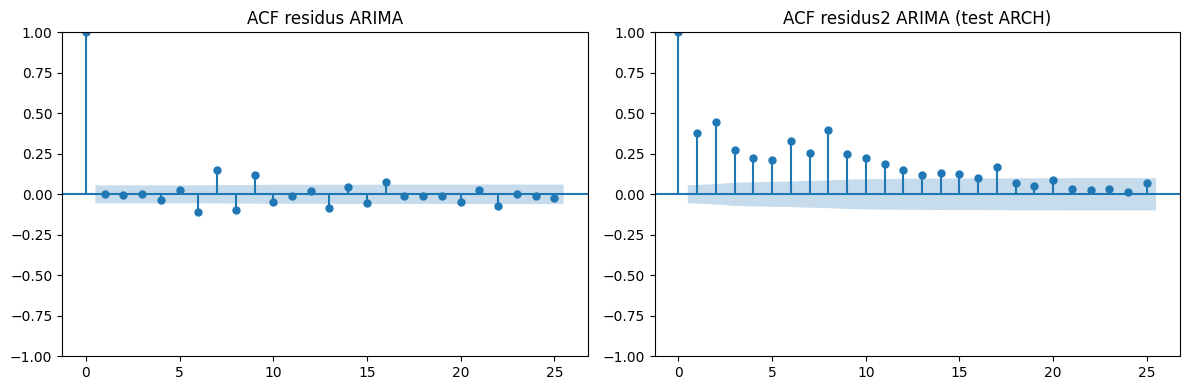


Figure sauvegardee : C:\Users\elbid\Documents\TREDING INTELEGENT\dia-quant-lab\reports\d03\figures\acf_residus_arima.png
CSV sauvegarde : C:\Users\elbid\Documents\TREDING INTELEGENT\dia-quant-lab\reports\d03\diagnostics_residus.csv


In [9]:
diag = residual_diagnostics(res_arima.residuals)

rows_lb = []
for lag, v in diag["ljung_box"].items():
    rows_lb.append({
        "Lag": lag,
        "LB stat (residus)": v["stat"],
        "p-value (residus)": v["pval"],
        "Rejette H0 (5%)": v["pval"] < 0.05,
        "LB stat (residus2)": diag["ljung_box_squared"][lag]["stat"],
        "p-value (residus2)": diag["ljung_box_squared"][lag]["pval"],
        "ARCH detecte (5%)": diag["ljung_box_squared"][lag]["pval"] < 0.05,
    })
df_lb = pd.DataFrame(rows_lb)
display(df_lb)

print()
jb = diag["jarque_bera"]
print("Jarque-Bera : stat = " + str(jb["stat"]) + "  |  p-value = " + str(jb["pval"]))
print("Normalite (p>=0.05) :", jb["normalite"])
print("Asymetrie :", diag["asymetrie"])
print("Exces de kurtosis :", diag["kurtosis_exces"])
print("Nombre de residus utilises :", diag["n_residus"])

r_resid = res_arima.residuals.dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(r_resid,     lags=25, ax=axes[0], title="ACF residus ARIMA")
plot_acf(r_resid**2,  lags=25, ax=axes[1], title="ACF residus2 ARIMA (test ARCH)")
plt.tight_layout()
fig.savefig(REP_FIG / "acf_residus_arima.png", dpi=120, bbox_inches="tight")
plt.show()
print()
print("Figure sauvegardee :", str(REP_FIG / "acf_residus_arima.png"))

rows_csv = []
for lag, v in diag["ljung_box"].items():
    rows_csv.append({
        "modele": res_arima.nom, "test": "ljung_box_residus",
        "lag": lag, "stat": v["stat"], "pval": v["pval"],
    })
for lag, v in diag["ljung_box_squared"].items():
    rows_csv.append({
        "modele": res_arima.nom, "test": "ljung_box_residus_carres",
        "lag": lag, "stat": v["stat"], "pval": v["pval"],
    })
rows_csv.append({
    "modele": res_arima.nom, "test": "jarque_bera",
    "lag": None, "stat": jb["stat"], "pval": jb["pval"],
})
pd.DataFrame(rows_csv).to_csv(REP_D03 / "diagnostics_residus.csv", index=False)
print("CSV sauvegarde :", str(REP_D03 / "diagnostics_residus.csv"))


## 6. Comparatif — fenêtre de validation (2023-01-03 -> 2024-12-31)

Toutes les prévisions utilisent des **paramètres gelés** estimés sur l'apprentissage.
Référence Campbell-Thompson : `historical_mean` (moyenne historique expansive décalée d'un pas).
Test de Diebold-Mariano (correction HLN) : H0 = égale précision vs `historical_mean`.
Le meilleur modèle (RMSE) sur cette fenêtre est retenu pour commentaire en section 7.


In [10]:
res_zero = naive_zero(frame)
res_last = naive_last(frame)
res_hm   = historical_mean(frame)

val_idx   = dec["validation"].index
y_val     = frame.loc[val_idx, "dia_ret"]
bench_val = res_hm.predictions.reindex(val_idx)

tous_modeles = {
    "naive_zero":      res_zero,
    "naive_last":      res_last,
    "historical_mean": res_hm,
    res_arima.nom:     res_arima,
    res_sarimax.nom:   res_sarimax,
}
for nom, res in resultats_sarima.items():
    if res is not None:
        tous_modeles[nom] = res

rows_val = []
for nom, res in tous_modeles.items():
    yhat = res.predictions.reindex(val_idx)
    m  = metrics(y_val, yhat, bench_val)
    dm = diebold_mariano(y_val, res_hm.predictions.reindex(val_idx), yhat)
    rows_val.append({
        "modele":      nom,
        "RMSE (%)":    m["rmse_pct"],
        "MAE (%)":     m["mae_pct"],
        "Dir acc":     m["dir_acc"],
        "R2_oos":      m["r2_oos"],
        "DM stat":     dm["dm_stat"],
        "DM p-value":  dm["pval"],
        "n":           m["n"],
    })

df_val = pd.DataFrame(rows_val).sort_values("RMSE (%)").reset_index(drop=True)
display(df_val)
df_val.to_csv(REP_D03 / "comparatif_validation.csv", index=False)

meilleur_val_nom = df_val.iloc[0]["modele"]
print()
print("CSV sauvegarde :", str(REP_D03 / "comparatif_validation.csv"))
print("Meilleur modele (validation, RMSE) :", meilleur_val_nom)


,modele,RMSE (%),MAE (%),Dir acc,R2_oos,DM stat,DM p-value,n
0,historical_mean,0.715243,0.543852,0.5578,0.000000,NaN,NaN,502
1,naive_zero,0.716944,0.547190,NaN,-0.004760,-1.1118,0.266746,502
2,"ARIMA(0,0,3)",0.734611,0.563686,0.4681,-0.054888,-3.1196,0.001915,502
3,"SARIMA(0,0,3)(1,0,1)[5]",0.734659,0.563562,0.4721,-0.055028,-3.1345,0.001823,502
4,"SARIMA(0,0,3)(0,0,1)[5]",0.735014,0.563236,0.4661,-0.056046,-3.2032,0.001445,502
5,"SARIMA(0,0,3)(1,0,0)[5]",0.735454,0.563591,0.4641,-0.057311,-3.2447,0.001254,502
6,"SARIMAX(0,0,3)+SPY(t-1)",0.736291,0.565908,0.4622,-0.059720,-3.3282,0.000939,502
7,naive_last,0.976919,0.759979,0.5418,-0.865561,-7.1708,0.000000,502



CSV sauvegarde : C:\Users\elbid\Documents\TREDING INTELEGENT\dia-quant-lab\reports\d03\comparatif_validation.csv
Meilleur modele (validation, RMSE) : historical_mean


## 7. Évaluation hors échantillon — fenêtre de test (2025-01-02 -> 2026-10-30)

Tous les modèles sont évalués sur le test avec les **mêmes paramètres gelés**.
Test de Diebold-Mariano (correction Harvey-Leybourne-Newbold) :
H0 = égale précision vs `historical_mean` (benchmark Campbell-Thompson).
La sélection du meilleur modèle était faite **avant** de regarder le test.


,modele,RMSE (%),MAE (%),Dir acc,R2_oos,DM stat,DM p-value,n
0,historical_mean,0.944156,0.657403,0.5459,0.000000,NaN,NaN,458
1,naive_zero,0.945211,0.659478,NaN,-0.002235,-0.6026,0.547056,458
2,"SARIMA(0,0,3)(0,0,1)[5]",0.952597,0.664319,0.5415,-0.017960,-0.6524,0.514474,458
3,"SARIMA(0,0,3)(1,0,0)[5]",0.954018,0.664285,0.5393,-0.020999,-0.7517,0.452594,458
4,"SARIMA(0,0,3)(1,0,1)[5]",0.954047,0.664415,0.5371,-0.021061,-0.7364,0.461844,458
5,"ARIMA(0,0,3)",0.954544,0.664675,0.5415,-0.022126,-0.7684,0.442654,458
6,"SARIMAX(0,0,3)+SPY(t-1)",0.954702,0.665238,0.5262,-0.022464,-0.8450,0.398569,458
7,naive_last,1.372750,0.969453,0.4607,-1.113952,-4.0576,0.000058,458


CSV sauvegarde : C:\Users\elbid\Documents\TREDING INTELEGENT\dia-quant-lab\reports\d03\comparatif_test.csv


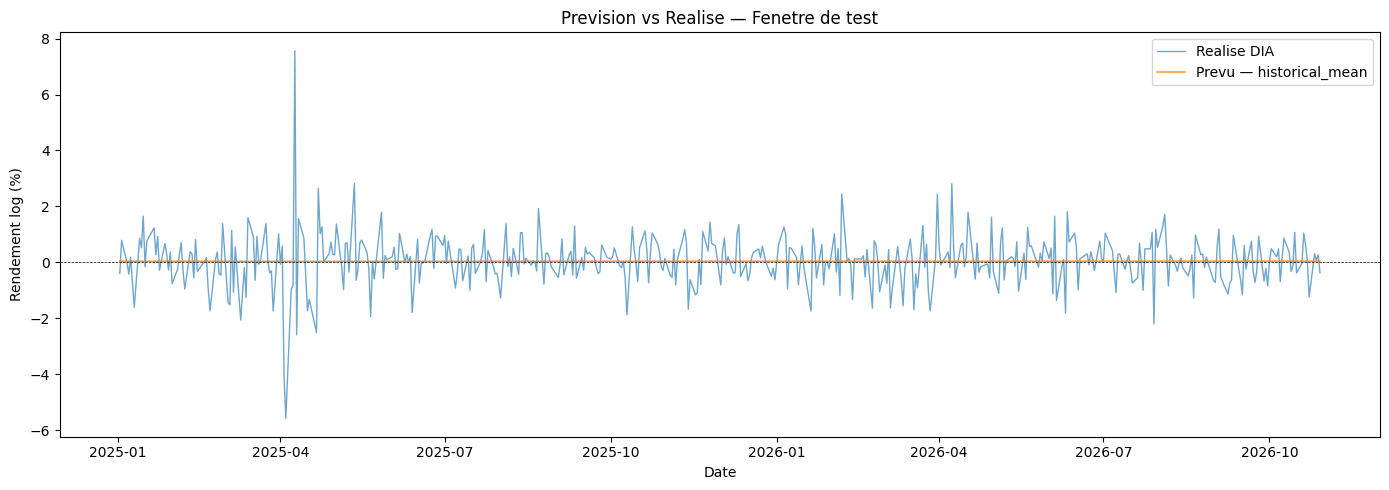

Figure sauvegardee : C:\Users\elbid\Documents\TREDING INTELEGENT\dia-quant-lab\reports\d03\figures\prevision_vs_realise_test.png


In [11]:
test_idx   = dec["test"].index
y_test     = frame.loc[test_idx, "dia_ret"]
bench_test = res_hm.predictions.reindex(test_idx)

rows_test = []
for nom, res in tous_modeles.items():
    yhat = res.predictions.reindex(test_idx)
    m    = metrics(y_test, yhat, bench_test)
    dm   = diebold_mariano(y_test, res_hm.predictions.reindex(test_idx), yhat)
    rows_test.append({
        "modele":      nom,
        "RMSE (%)":    m["rmse_pct"],
        "MAE (%)":     m["mae_pct"],
        "Dir acc":     m["dir_acc"],
        "R2_oos":      m["r2_oos"],
        "DM stat":     dm["dm_stat"],
        "DM p-value":  dm["pval"],
        "n":           m["n"],
    })

df_test = pd.DataFrame(rows_test).sort_values("RMSE (%)").reset_index(drop=True)
display(df_test)
df_test.to_csv(REP_D03 / "comparatif_test.csv", index=False)
print("CSV sauvegarde :", str(REP_D03 / "comparatif_test.csv"))

meilleur_test_nom = df_test.iloc[0]["modele"]
res_meilleur = tous_modeles[meilleur_test_nom]
yhat_best = res_meilleur.predictions.reindex(test_idx)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(y_test.index, y_test.values * 100,
        label="Realise DIA", color="#1f77b4", alpha=0.65, lw=1)
ax.plot(yhat_best.index, yhat_best.values * 100,
        label="Prevu — " + meilleur_test_nom,
        color="#ff7f0e", alpha=0.85, lw=1.1)
ax.axhline(0, color="black", lw=0.5, ls="--")
ax.set_xlabel("Date")
ax.set_ylabel("Rendement log (%)")
ax.set_title("Prevision vs Realise — Fenetre de test")
ax.legend()
plt.tight_layout()
fig.savefig(REP_FIG / "prevision_vs_realise_test.png", dpi=120, bbox_inches="tight")
plt.show()
print("Figure sauvegardee :", str(REP_FIG / "prevision_vs_realise_test.png"))


In [12]:
# previsions_datees.csv : validation + test uniquement
# Colonnes : date_cible (index), date_prevision (J-1 ouvre), fenetre,
#            dia_ret_realise, [un modele par colonne]
val_test_idx = dec["validation"].index.append(dec["test"].index).sort_values()

full_idx = frame.index
prev_map = {}
for i, d in enumerate(full_idx):
    prev_map[d] = full_idx[i - 1] if i > 0 else pd.NaT

fenetre_map = {}
for d in dec["validation"].index:
    fenetre_map[d] = "validation"
for d in dec["test"].index:
    fenetre_map[d] = "test"

df_prev = pd.DataFrame({
    "date_prevision":  [prev_map.get(d, pd.NaT) for d in val_test_idx],
    "fenetre":         [fenetre_map[d] for d in val_test_idx],
    "dia_ret_realise": frame.loc[val_test_idx, "dia_ret"].values,
})
df_prev.index = val_test_idx
df_prev.index.name = "date_cible"

for nom, res in tous_modeles.items():
    df_prev[nom] = res.predictions.reindex(val_test_idx).values

df_prev.to_csv(REP_D03 / "previsions_datees.csv")
print("CSV sauvegarde :", str(REP_D03 / "previsions_datees.csv"))
print("Forme :", df_prev.shape)
print("Fenetres :", df_prev["fenetre"].value_counts().to_dict())

rows_temps = []
for nom, res in tous_modeles.items():
    rows_temps.append({
        "modele":           nom,
        "fit_secondes":     round(res.fit_seconds, 4),
        "predict_secondes": round(res.predict_seconds, 4),
        "total_secondes":   round(res.fit_seconds + res.predict_seconds, 4),
    })
df_temps = (
    pd.DataFrame(rows_temps)
    .sort_values("total_secondes", ascending=False)
    .reset_index(drop=True)
)
display(df_temps)
df_temps.to_csv(REP_D03 / "temps_calcul.csv", index=False)
print("CSV sauvegarde :", str(REP_D03 / "temps_calcul.csv"))


CSV sauvegarde : C:\Users\elbid\Documents\TREDING INTELEGENT\dia-quant-lab\reports\d03\previsions_datees.csv
Forme : (960, 11)
Fenetres : {'validation': 502, 'test': 458}


,modele,fit_secondes,predict_secondes,total_secondes
0,"SARIMA(0,0,3)(1,0,1)[5]",2.7765,0.0728,2.8493
1,"SARIMA(0,0,3)(0,0,1)[5]",2.5212,0.0554,2.5766
2,"SARIMAX(0,0,3)+SPY(t-1)",2.2652,0.0468,2.3120
3,"ARIMA(0,0,3)",1.4153,0.0604,1.4757
4,"SARIMA(0,0,3)(1,0,0)[5]",0.8642,0.0421,0.9063
5,historical_mean,0.0000,0.0010,0.0010
6,naive_last,0.0000,0.0005,0.0005
7,naive_zero,0.0000,0.0003,0.0003


CSV sauvegarde : C:\Users\elbid\Documents\TREDING INTELEGENT\dia-quant-lab\reports\d03\temps_calcul.csv


## 8. Conclusion

### 1. Stationnarité — d = 0 justifié

Le test ADF rejette la racine unitaire pour DIA (stat = −10.90, p = 0.0) et pour SPY
(stat = −10.86, p = 0.0) sur la fenêtre d'apprentissage.
Les rendements log sont stationnaires : d = 0 est justifié sans différenciation.

### 2. Structure MA de court terme — ordre faible

La grille AIC sélectionne ARIMA(0,0,3) (AIC = −7267.17, BIC = −7241.48).
ARIMA(0,0,2) est quasi équivalent en AIC (−7267.14, écart = 0.03) mais préféré par le BIC
(−7246.59 vs −7241.48), qui pénalise davantage le paramètre supplémentaire.
Ces deux ordres sont pratiquement indistinguables : la structure temporelle des rendements
DIA est faible et de très courte portée (deux à trois retards MA au plus).
L'intercept n'est pas significatif (p = 0.45), ce qui est cohérent avec l'hypothèse de rendement
moyen nul sur l'horizon journalier.

### 3. Saisonnalité hebdomadaire rejetée

Les trois variantes SARIMA dégradent l'AIC par rapport à l'ARIMA de base :
SARIMA(0,0,3)(1,0,0)[5] : AIC = −7266.09, SARIMA(0,0,3)(0,0,1)[5] : AIC = −7266.25,
SARIMA(0,0,3)(1,0,1)[5] : AIC = −7263.21.
Les termes saisonniers ne sont pas significatifs ou à peine : ar.S.L5 dans (1,0,0)[5] affiche
p = 0.052, et dans (1,0,1)[5] les deux termes saisonniers ont des p-values proches de 0.90.
Seul ma.S.L5 dans (0,0,1)[5] atteint p = 0.032, mais l'AIC se dégrade quand même.
**Conclusion : il n'existe pas de cycle hebdomadaire exploitable dans les rendements DIA.**

### 4. SPY(t−1) non significatif

Dans le SARIMAX, le coefficient de spy_ret_{t−1} vaut 0.067 avec p = 0.421 (non significatif).
L'AIC se dégrade à −7259.08 contre −7267.17 pour l'ARIMA seul.
Le rendement du S&P 500 de la veille n'apporte pas d'information prédictive supplémentaire
sur le rendement du DIA aujourd'hui, au-delà de ce que les termes MA capturent déjà.

### 5. Aucun modèle ne bat la moyenne historique

Sur la **validation** : tous les modèles économétriques ont un R²_oos négatif
(ARIMA(0,0,3) : R²_oos = −0.055, SARIMAX : R²_oos = −0.060).
Le test de Diebold-Mariano confirme qu'ils sont significativement moins précis que la moyenne
historique (ARIMA : DM = −3.12, p = 0.0019 ; SARIMAX : DM = −3.33, p = 0.0009).
Sur le **test** : les DM ne sont plus significatifs (ARIMA : p = 0.44, SARIMAX : p = 0.40),
mais les R²_oos restent négatifs — les modèles ne surpassent pas le benchmark même là.
Ces résultats s'accordent avec l'hypothèse d'efficience des marchés sur les grands indices liquides.

### 6. SARIMAX comme baseline B09 pour D05

Malgré ses limites, SARIMAX(0,0,3)+SPY(t-1) reste la baseline économétrique de référence
pour la variante B09. Les modèles ML/DL (D05) devront le battre en termes de RMSE, de R²_oos
et de test DM pour justifier leur complexité supplémentaire.
La barre est basse en valeur absolue (RMSE ≈ 0.95 % sur le test), mais elle est difficile
à franchir statistiquement, comme le montrent les DM sur la validation.

### 7. Limites et perspectives

- **Autocorrélation résiduelle** (LB lag = 10, p = 0.0) : des effets non linéaires subsistent
  dans les résidus malgré les termes MA. Un modèle de la variance conditionnelle est nécessaire.
- **Effets ARCH** (LB² lag = 10, p = 0.0) : la volatilité est hétéroscédastique → D04 (GARCH).
- **Résidus non normaux** (JB p = 0.0, kurtosis = 17.48, asymétrie = −0.87) : les queues
  épaisses impliquent que les intervalles de confiance gaussiens sous-estiment le risque extrême.
- **Cible clôture-clôture** : le modèle prédit le rendement de clôture t+1, mais l'ordre
  s'exécute à l'ouverture t+1 — le glissement entre ouverture et clôture n'est pas capturé → D06.
